# Mutual Fund Analysis project

 project goal

The goal of this project is to analyze mutual fund data using Python and identify important factors such as risk, return, expense ratio, fund size, fund age, and investment options like SIP and lumpsum. The analysis aims to understand and compare the performance and risk characteristics of different mutual funds.

 Who Benefits from the Final Output?

Investors: Can compare mutual funds based on risk, return, and other important factors before making investment decisions.
Financial Advisors: Can use the analysis to provide data-based information to their clients.
Fund Managers and AMCs: Can gain insights into fund performance and risk factors.
Data Analysts: Can demonstrate data analysis, visualization, and Python skills through this project.

 Overall Benefit

The project converts raw mutual fund data into meaningful insights, making it easier to understand and compare different mutual funds.



Why is it important to balance return and risk together rather than simply ranking funds by highest
return? Give an example of how a high-return fund could still be a poor choice.

“It is important to consider both return and risk because a high-return fund may also have a high risk level. For example, in our dataset, a fund with a 3-year return of 24.6% has a risk level of 6. Although the return is high, the investor should also consider the higher risk before selecting the fund. Therefore, mutual funds should be compared using both return and risk rather than return alone.”





 Project Objectives

The main objectives of this  projects are 
prepare the mutual fund To clean and prepare the mutual fund dataset by identifying missing values, duplicate records, and inconsistent data.

To analyze mutual fund performance using 1-year, 3-year, and 5-year returns.

To analyze the relationship between risk and return using risk level and different return measures.

To compare mutual funds based on risk level, rating, category, sub-category, and historical returns.

To create meaningful visualizations and an interactive dashboard using Python, Excel, and Power BI to present the key insights clearly.


Role of Python, Excel, and Power BI

Using all three tools provides a complete data analysis workflow:

Python → Data Cleaning & Analysis → Excel → Data Checking & Validation → Power BI → Interactive Dashboard & Reporting

Each tool has different strengths. Python is useful for detailed analysis, Excel is useful for easy data checking and calculations, and Power BI is useful for interactive visualization and presentation. Using all three gives a more complete and professional analysis.



In [6]:
import pandas as pd

df = pd.read_csv("comprehensive_mutual_funds_data project.csv")

print(df.head())

                                         scheme_name  min_sip  min_lumpsum  \
0  Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...      100          100   
1                     Aditya Birla SL Arbitrage Fund     1000         1000   
2     Aditya Birla SL Asset Allocator FoF-Dir Growth     1000         1000   
3   Aditya Birla SL Bal Bhavishya Yojna – Dir Growth      500         1000   
4            Aditya Birla SL Balanced Advantage Fund      100          100   

   expense_ratio  fund_size_cr  fund_age_yr        fund_manager sortino  \
0           0.27          10.0           10      Kaustubh Gupta    0.32   
1           0.36        4288.0           10    Lovelish Solanki    1.33   
2           0.53         157.0           10  Vinod Narayan Bhat    3.44   
3           0.76         637.0            4         Atul Penkar    2.18   
4           0.61        6386.0           10        Mohit Sharma    3.69   

   alpha     sd  beta sharpe  risk_level                           amc_name  \
0

In [7]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 814
Number of Columns: 20


The mutual fund dataset contains 814 rows and 20 columns. Each row represents a mutual fund scheme, while the columns contain information about the fund's investment requirements, performance, risk, fund age, AMC, and category.


In [9]:
print(df.columns.tolist())

['scheme_name', 'min_sip', 'min_lumpsum', 'expense_ratio', 'fund_size_cr', 'fund_age_yr', 'fund_manager', 'sortino', 'alpha', 'sd', 'beta', 'sharpe', 'risk_level', 'amc_name', 'rating', 'category', 'sub_category', 'returns_1yr', 'returns_3yr', 'returns_5yr']


Which columns are unnecessary?
fund_manager

Reason: The individual manager's name is not directly required for analysing fund performance, returns, risk, or cost. It is also a high-cardinality text field.

In [10]:
df = df.drop(columns=['fund_manager'])

print(df.shape)

(814, 19)


Missing Values

In [11]:
print(df.isnull().sum())


scheme_name        0
min_sip            0
min_lumpsum        0
expense_ratio      0
fund_size_cr       0
fund_age_yr        0
sortino            0
alpha              0
sd                 0
beta               0
sharpe             0
risk_level         0
amc_name           0
rating             0
category           0
sub_category       0
returns_1yr        0
returns_3yr       21
returns_5yr      167
dtype: int64


Missing Value Analysis:
The dataset contains missing values in returns_3yr and returns_5yr. There are 21 missing values (2.58%) in returns_3yr and 167 missing values (20.52%) in returns_5yr. All other columns have no missing values. Since the percentage of missing values in returns_3yr is small, median imputation can be used. For returns_5yr, the missing percentage is relatively high, so the missing values will be retained and excluded when performing analyses specifically based on 5-year returns.

In [12]:
print(df.dtypes)

scheme_name          str
min_sip            int64
min_lumpsum        int64
expense_ratio    float64
fund_size_cr     float64
fund_age_yr        int64
sortino              str
alpha                str
sd                   str
beta                 str
sharpe               str
risk_level         int64
amc_name             str
rating             int64
category             str
sub_category         str
returns_1yr      float64
returns_3yr      float64
returns_5yr      float64
dtype: object


In [13]:
print(df[['sortino', 'alpha', 'sd', 'beta', 'sharpe']].head(10))

  sortino  alpha     sd   beta sharpe
0    0.32   2.24   9.39   0.01   0.24
1    1.33   1.53   0.72   0.56    1.1
2    3.44   2.67  10.58   0.67   1.42
3    2.18  -6.37  14.99   0.85    0.9
4    3.69   1.99  10.38   0.68   1.39
5    2.07   1.24  25.53   0.96   0.97
6    1.92   4.46   1.91   1.78   1.09
7    1.42      -  20.18      -   1.06
8    2.28   2.38   1.93   0.78   1.35
9    1.82   3.01    2.9  -0.95   1.47


In [14]:
cols = ['sortino', 'alpha', 'sd', 'beta', 'sharpe']

df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')

In [15]:
print(df[cols].dtypes)

sortino    float64
alpha      float64
sd         float64
beta       float64
sharpe     float64
dtype: object


Standardisation of Numeric Formats:
The columns sortino, alpha, sd, beta, and sharpe were stored as string values even though they contained numerical decimal values. These columns were converted into numeric (float) format using Pandas. This ensures that the values can be properly used for mathematical calculations, statistical analysis, and visualisation. Other numerical columns such as expense_ratio, fund_size_cr, and returns_1yr, returns_3yr, and returns_5yr were already in the correct numeric format.


In [16]:
numeric_cols = [
    'min_sip', 'min_lumpsum', 'expense_ratio', 'fund_size_cr',
    'fund_age_yr', 'sortino', 'alpha', 'sd', 'beta', 'sharpe',
    'rating', 'returns_1yr', 'returns_3yr', 'returns_5yr'
]

summary = df[numeric_cols].describe().T

print(summary)

               count         mean          std    min       25%       50%  \
min_sip        814.0   528.500000   369.184517   0.00  150.0000   500.000   
min_lumpsum    814.0  3047.468059  2514.619513   0.00  500.0000  5000.000   
expense_ratio  814.0     0.713231     0.482161   0.00    0.3100     0.615   
fund_size_cr   814.0  3812.854214  7181.479475   2.38  175.2500   940.500   
fund_age_yr    814.0     8.319410     2.640622   1.00    6.0000    10.000   
sortino        791.0     2.652642     1.392228  -1.77    1.7500     2.870   
alpha          772.0     2.505635     3.951573 -13.36    0.5300     1.855   
sd             790.0    10.272696     7.805667   0.27    2.1625    12.300   
beta           772.0     0.822241     1.309871 -31.86    0.7000     0.860   
sharpe         791.0     1.204185     0.536431  -0.82    0.9300     1.290   
rating         814.0     2.641278     1.463476   0.00    2.0000     3.000   
returns_1yr    814.0     3.921376     6.675502 -19.70    1.5000     4.400   

In [17]:
stats = pd.DataFrame({
    'Mean': df[numeric_cols].mean(),
    'Median': df[numeric_cols].median(),
    'Mode': df[numeric_cols].mode().iloc[0],
    'Min': df[numeric_cols].min(),
    'Max': df[numeric_cols].max(),
    'Standard Deviation': df[numeric_cols].std()
})

print(stats)

                      Mean    Median     Mode    Min       Max  \
min_sip         528.500000   500.000   500.00   0.00   2000.00   
min_lumpsum    3047.468059  5000.000  5000.00   0.00  25000.00   
expense_ratio     0.713231     0.615     0.21   0.00      2.59   
fund_size_cr   3812.854214   940.500    90.00   2.38  57052.00   
fund_age_yr       8.319410    10.000    10.00   1.00     17.00   
sortino           2.652642     2.870     3.24  -1.77     12.57   
alpha             2.505635     1.855     0.67 -13.36     27.24   
sd               10.272696    12.300     0.38   0.27     77.72   
beta              0.822241     0.860     0.94 -31.86      5.40   
sharpe            1.204185     1.290     1.40  -0.82      3.52   
rating            2.641278     3.000     3.00   0.00      5.00   
returns_1yr       3.921376     4.400     5.60 -19.70    130.80   
returns_3yr      18.525347    18.500     3.90   3.30     71.40   
returns_5yr       9.490726     8.900     5.30  -4.10     23.20   

         

nterpretation:
The statistical summary shows that a typical mutual fund in the dataset has a minimum SIP requirement of around ₹500 and a fund age of approximately 8–10 years. The average expense ratio is around 0.71%, while the typical fund has a rating close to 3. The average 1-year return is about 3.92%, the average 3-year return is about 18.53%, and the average 5-year return is about 9.49%. The large difference between the mean and median for fund size indicates that a few very large funds significantly influence the average. The return measures also show considerable variation, suggesting differences in fund performance.

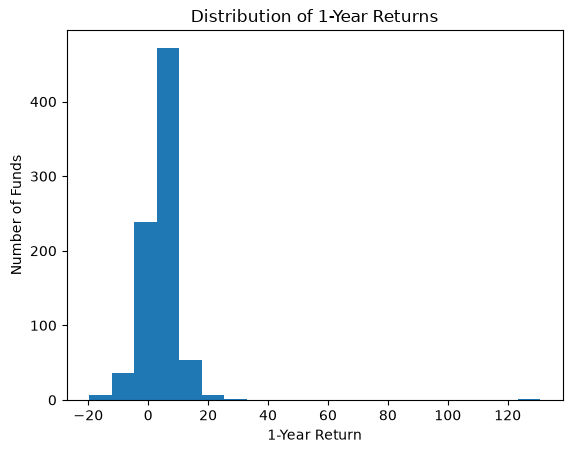

In [18]:
import matplotlib.pyplot as plt

plt.hist(df['returns_1yr'].dropna(), bins=20)
plt.xlabel('1-Year Return')
plt.ylabel('Number of Funds')
plt.title('Distribution of 1-Year Returns')
plt.show()

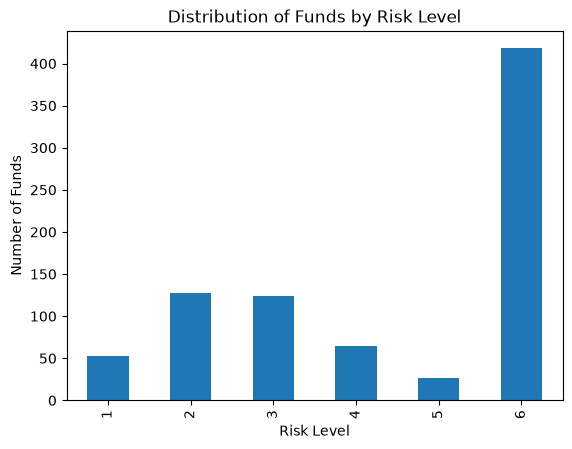

In [19]:
df['risk_level'].value_counts().sort_index().plot(kind='bar')

plt.xlabel('Risk Level')
plt.ylabel('Number of Funds')
plt.title('Distribution of Funds by Risk Level')
plt.show()

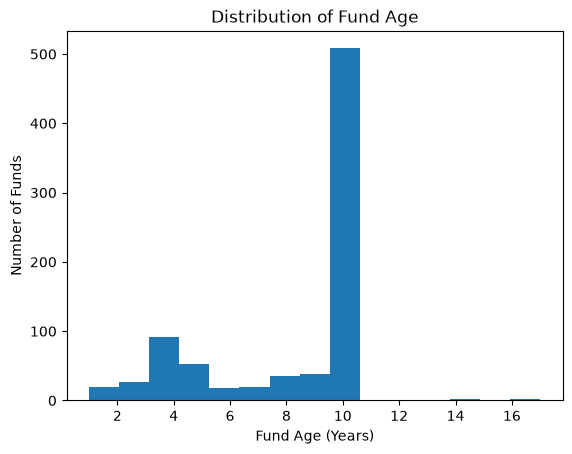

In [20]:
plt.hist(df['fund_age_yr'], bins=15)
plt.xlabel('Fund Age (Years)')
plt.ylabel('Number of Funds')
plt.title('Distribution of Fund Age')
plt.show()

 Why is normalisation necessary ?
 Normalization is necessary because the numerical fields have different scales and ranges. Without normalization, variables with larger numerical values could dominate the combined score, even if they are not more important. MinMaxScaler converts the selected variables to a common 0–1 scale, making them suitable for fair comparison and scoring.

In [8]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

fields_to_scale = [
    'returns_1yr',
    'returns_3yr',
    'expense_ratio',
    'fund_age_yr'
]

df_scaled = df.copy()

df_scaled[[col + '_scaled' for col in fields_to_scale]] = scaler.fit_transform(
    df[fields_to_scale]
)

df_scaled.head()

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,...,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr,returns_1yr_scaled,returns_3yr_scaled,expense_ratio_scaled,fund_age_yr_scaled
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,100,100,0.27,10.0,10,Kaustubh Gupta,0.32,2.24,9.39,...,3,Other,FoFs Domestic,4.0,6.5,6.9,0.157475,0.046990,0.104247,0.5625
1,Aditya Birla SL Arbitrage Fund,1000,1000,0.36,4288.0,10,Lovelish Solanki,1.33,1.53,0.72,...,3,Hybrid,Arbitrage Mutual Funds,5.6,4.8,5.5,0.168106,0.022026,0.138996,0.5625
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,1000,1000,0.53,157.0,10,Vinod Narayan Bhat,3.44,2.67,10.58,...,3,Other,FoFs Domestic,2.0,18.9,9.7,0.144186,0.229075,0.204633,0.5625
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,...,2,Solution Oriented,Childrens Funds,-0.7,17.1,NaN,0.126246,0.202643,0.293436,0.1875
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,...,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7,0.160797,0.224670,0.235521,0.5625


In [9]:
df_scaled[
    ['returns_1yr', 'returns_1yr_scaled',
     'returns_3yr', 'returns_3yr_scaled',
     'expense_ratio', 'expense_ratio_scaled',
     'fund_age_yr', 'fund_age_yr_scaled']
].head(10)

,returns_1yr,returns_1yr_scaled,returns_3yr,returns_3yr_scaled,expense_ratio,expense_ratio_scaled,fund_age_yr,fund_age_yr_scaled
0,4.0,0.157475,6.5,0.046990,0.27,0.104247,10,0.5625
1,5.6,0.168106,4.8,0.022026,0.36,0.138996,10,0.5625
2,2.0,0.144186,18.9,0.229075,0.53,0.204633,10,0.5625
3,-0.7,0.126246,17.1,0.202643,0.76,0.293436,4,0.1875
4,4.5,0.160797,18.6,0.224670,0.61,0.235521,10,0.5625
5,5.3,0.166113,24.6,0.312775,1.17,0.451737,9,0.5000
6,4.5,0.160797,6.8,0.051395,0.37,0.142857,10,0.5625
7,-10.3,0.062458,29.4,0.383260,1.29,0.498069,10,0.5625
8,4.9,0.163455,7.1,0.055800,0.31,0.119691,10,0.5625
9,8.7,0.188704,9.0,0.083700,0.69,0.266409,8,0.4375


In [10]:
df_scaled.columns.tolist()

['scheme_name',
 'min_sip',
 'min_lumpsum',
 'expense_ratio',
 'fund_size_cr',
 'fund_age_yr',
 'fund_manager',
 'sortino',
 'alpha',
 'sd',
 'beta',
 'sharpe',
 'risk_level',
 'amc_name',
 'rating',
 'category',
 'sub_category',
 'returns_1yr',
 'returns_3yr',
 'returns_5yr',
 'returns_1yr_scaled',
 'returns_3yr_scaled',
 'expense_ratio_scaled',
 'fund_age_yr_scaled']

In [11]:
df_scaled[
    ['returns_1yr', 'returns_1yr_scaled',
     'returns_3yr', 'returns_3yr_scaled',
     'expense_ratio', 'expense_ratio_scaled',
     'fund_age_yr', 'fund_age_yr_scaled']
].head(10)

,returns_1yr,returns_1yr_scaled,returns_3yr,returns_3yr_scaled,expense_ratio,expense_ratio_scaled,fund_age_yr,fund_age_yr_scaled
0,4.0,0.157475,6.5,0.046990,0.27,0.104247,10,0.5625
1,5.6,0.168106,4.8,0.022026,0.36,0.138996,10,0.5625
2,2.0,0.144186,18.9,0.229075,0.53,0.204633,10,0.5625
3,-0.7,0.126246,17.1,0.202643,0.76,0.293436,4,0.1875
4,4.5,0.160797,18.6,0.224670,0.61,0.235521,10,0.5625
5,5.3,0.166113,24.6,0.312775,1.17,0.451737,9,0.5000
6,4.5,0.160797,6.8,0.051395,0.37,0.142857,10,0.5625
7,-10.3,0.062458,29.4,0.383260,1.29,0.498069,10,0.5625
8,4.9,0.163455,7.1,0.055800,0.31,0.119691,10,0.5625
9,8.7,0.188704,9.0,0.083700,0.69,0.266409,8,0.4375


After Min-Max scaling, returns and expense ratios are converted to a common 0–1 scale. This makes it easier to compare their relative magnitude and identify differences between funds. Before scaling, returns and expense ratios had different units and ranges, making direct comparison difficult. After scaling, higher and lower values can be easily compared on the same scale.

In [15]:
return_score = df_scaled['returns_3yr_scaled']
expense_score = 1 - df_scaled['expense_ratio_scaled']

target_age = 9

age_score = 1 - abs(df_scaled['fund_age_yr'] - target_age) / df_scaled['fund_age_yr'].max()
age_score = age_score.clip(0, 1)

positive_1yr_score = (df_scaled['returns_1yr'] > 0).astype(int)

In [18]:
df_scaled['final_score'] = (
    0.40 * return_score +
    0.25 * expense_score +
    0.20 * age_score +
    0.15 * positive_1yr_score
)

In [19]:
df_scaled[['scheme_name', 'final_score']].head(10)

,scheme_name,final_score
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,0.580969
1,Aditya Birla SL Arbitrage Fund,0.562297
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,0.628707
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,0.398875
4,Aditya Birla SL Balanced Advantage Fund,0.619223
5,Aditya Birla SL Banking&Financial Services-Dir...,0.612176
6,Aditya Birla SL Banking&PSU Debt Fund,0.573079
7,Aditya Birla SL CEF – Global Agri Plan-Direct ...,0.467022
8,Aditya Birla SL Corporate Bond Fund,0.580633
9,Aditya Birla SL Credit Risk Fund,0.555113


In [20]:
df_ranked = df_scaled.sort_values(
    by='final_score',
    ascending=False
).reset_index(drop=True)

df_ranked['Rank'] = df_ranked.index + 1

df_ranked[
    ['Rank',
     'scheme_name',
     'returns_3yr',
     'expense_ratio',
     'fund_age_yr',
     'returns_1yr',
     'final_score']
].head(10)

,Rank,scheme_name,returns_3yr,expense_ratio,fund_age_yr,returns_1yr,final_score
0,1,Quant Small Cap Fund,71.4,0.64,10,5.4,0.926459
1,2,Quant Infrastructure Fund,61.5,0.64,10,5.6,0.868309
2,3,Quant Tax Plan- Direct Growth,54.9,0.57,10,0.9,0.836300
3,4,Quant Flexi Cap Fund,47.7,0.58,10,6.8,0.793044
4,5,PGIM India Midcap Opportunities Fund,42.9,0.46,9,2.0,0.788198
5,6,Quant Active Fund,45.5,0.58,10,1.0,0.780122
6,7,Quant Mid Cap Fund,45.1,0.63,10,8.8,0.772946
7,8,HSBC Small Cap Fund,44.7,0.77,9,5.1,0.768847
8,9,Nippon India Small Cap Fund,47.6,0.86,10,8.7,0.765429
9,10,Quant Multi Asset Fund,42.6,0.56,10,10.6,0.765018


The funds were ranked based on the final weighted score. Quant Small Cap Fund achieved the highest score of 0.926459, followed by Quant Infrastructure Fund with 0.868309 and Quant Tax Plan – Direct Growth with 0.836300. The factors that most strongly drive a high score are high 3-year returns and low expense ratios, as these factors have the highest weights of 40% and 25%, respectively. Moderate fund age and a positive 1-year return also contribute to the score. Therefore, funds with strong long-term returns, lower expenses, a moderate operating history, and positive recent returns tend to receive higher scores.

In [28]:
top30 = df_ranked.head(30).copy()

top30['Rank'] = range(1, 31)

top30 = top30[
    ['Rank',
     'scheme_name',
     'final_score',
     'min_sip',
     'min_lumpsum',
     'expense_ratio',
     'fund_size_cr',
     'fund_age_yr',
     'fund_manager',
     'risk_level',
     'rating',
     'category',
     'sub_category',
     'amc_name',
     'returns_1yr',
     'returns_3yr',
     'returns_5yr']
]

top30 = top30.reset_index(drop=True)

top30.to_excel(
    'Top_30_Mutual_Funds_Final.xlsx',
    index=False
)

print("Final Top 30 Excel file created successfully!")
print("Rows:", len(top30))
print("Columns:", len(top30.columns))

Final Top 30 Excel file created successfully!
Rows: 30
Columns: 17


In [29]:
print(top30.columns.tolist())

['Rank', 'scheme_name', 'final_score', 'min_sip', 'min_lumpsum', 'expense_ratio', 'fund_size_cr', 'fund_age_yr', 'fund_manager', 'risk_level', 'rating', 'category', 'sub_category', 'amc_name', 'returns_1yr', 'returns_3yr', 'returns_5yr']


In [30]:
import os

print(os.path.abspath('Top_30_Mutual_Funds_Ranking.xlsx'))

C:\Users\DELL\Desktop\labmetrics projects\Top_30_Mutual_Funds_Ranking.xlsx
